# MATPLOTLIB MASTERY — NOTEBOOK 5
## Chapters 36–45: Log Scales → Symmetric Log → Date/Time Visualization → Matplotlib+Pandas → Matplotlib+NumPy → EDA Workflow → Univariate → Bivariate → Multivariate → Correlation Visualization

Continuing directly from Notebook 4. Run all cells in order.

### Progress Tracker (this notebook)
- [x] Chapter 36 — Logarithmic Scales
- [x] Chapter 37 — Symmetric Log Scale
- [x] Chapter 38 — Date/Time Visualization
- [x] Chapter 39 — Matplotlib + Pandas
- [x] Chapter 40 — Matplotlib + NumPy
- [x] Chapter 41 — EDA with Matplotlib
- [x] Chapter 42 — Univariate Analysis
- [x] Chapter 43 — Bivariate Analysis
- [x] Chapter 44 — Multivariate Visualization
- [x] Chapter 45 — Correlation Visualization


In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
np.random.seed(42)


---
# CHAPTER 36 — LOGARITHMIC SCALES

## 1. Concept
`ax.set_yscale("log")` (or `"xscale"`) transforms an axis so equal *visual* distances represent equal *multiplicative* (not additive) steps — e.g., the gap from 1→10 looks the same as the gap from 10→100.

## 2. Why It Matters
Linear axes compress small values into invisibility whenever the data spans several orders of magnitude — a classic case where "technically plotting all the data" still produces an uninformative chart. Log scales are essential for:
- **Exponential growth/decay** (viral spread, compound interest, radioactive decay).
- **Power-law distributed data** (city populations, word frequencies, many financial/network metrics).
- Any dataset where you care about *relative* (percentage) change, not absolute change, across a huge range.

## 3–4. NumPy / Pandas Connection
Log scales are a pure Axes-display transform — they don't touch your underlying NumPy array or DataFrame column at all; you keep plotting the original values, and only the *axis* changes how it's rendered (contrast this with actually taking `np.log(data)` before plotting, a different, data-transforming choice discussed below).


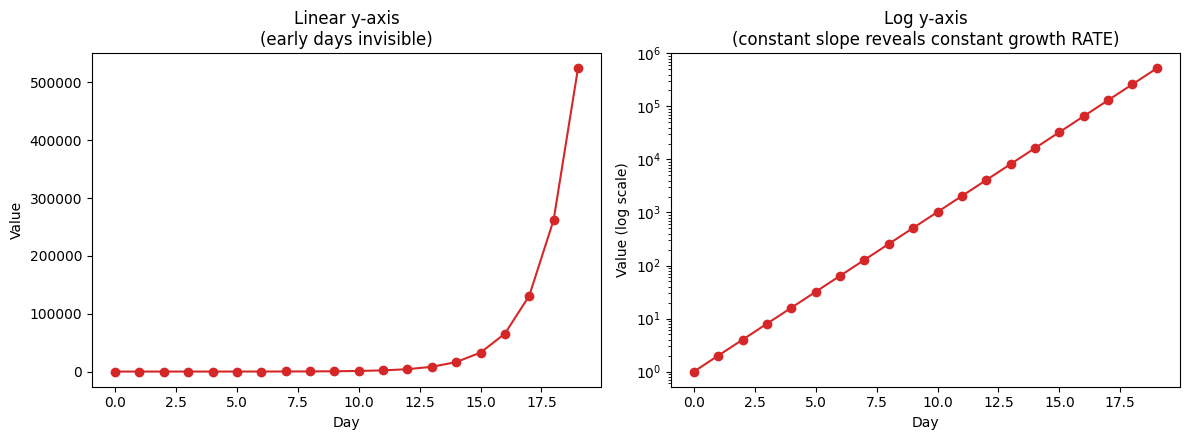

In [2]:
days_log = np.arange(0, 20)
linear_growth = days_log * 5
exponential_growth = 2 ** days_log   # doubles every day — classic exponential

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(days_log, exponential_growth, marker="o", color="tab:red")
axes[0].set_title("Linear y-axis\n(early days invisible)")
axes[0].set_xlabel("Day")
axes[0].set_ylabel("Value")

axes[1].plot(days_log, exponential_growth, marker="o", color="tab:red")
axes[1].set_yscale("log")
axes[1].set_title("Log y-axis\n(constant slope reveals constant growth RATE)")
axes[1].set_xlabel("Day")
axes[1].set_ylabel("Value (log scale)")

plt.tight_layout()
plt.show()


### Line-by-Line / Interpretation
- Left panel (linear): days 0–12 all look like they're at "zero" — the y-axis is dominated by the huge values from days 15–19, hiding all early detail.
- Right panel (log): the curve becomes a **straight line** — this is the single most important visual signature of exponential growth on a log axis, and instantly reveals that the growth *rate* (not just the absolute value) is constant across the whole period. A straight line on a log-y axis is the standard visual test analysts use to confirm "is this actually exponential?"

### Parameter Explanation
- `ax.set_yscale("log")` / `ax.set_xscale("log")` — apply independently to either axis (a **log-log plot**, both axes logged, is the standard way to visually detect power-law relationships).
- `ax.set_yscale("log", base=2)` — use a non-default logarithm base (base 10 is default) — base 2 is natural for "doubling time" data like the example above.

### Common Mistakes
- Applying `np.log()` to the data itself **and** also setting `ax.set_yscale("log")` — double-transforms the data, badly distorting the chart. Pick one: either transform the data and keep a linear axis (labeling the axis "log(value)"), or keep raw data and log-scale the axis (labeling the axis "value (log scale)") — never both.
- Attempting a log scale on data containing zero or negative values — `log(0)` and `log(negative)` are undefined; Matplotlib will silently drop/warn about those points. Use `symlog` (Chapter 37) if your data spans zero.
- Using a log axis on data that doesn't actually span multiple orders of magnitude — provides no benefit and makes the axis harder for a general audience to read intuitively.

### Debugging
If a log-scaled plot appears to be missing data points at the low end, check `data.min()` — any zero or negative values are silently excluded from a pure log axis (a frequent surprise when log-scaling raw counts that can legitimately be zero).

### Best Practices
- Reach for a log scale specifically when data spans 2+ orders of magnitude, or when relative/percentage change (not absolute change) is the analytically meaningful quantity.
- Always label the axis explicitly as "(log scale)" so readers aren't misled about the underlying values' true spacing.

### Interview Insight
**Q: How would you visually confirm that a growth process is exponential, not just fast-growing linear or polynomial growth?**
A: Plot it on a log-scaled y-axis (linear x-axis) — a straight line is the signature of exponential growth on this scale; polynomial or linear growth would instead curve. For confirming a power-law relationship between two variables, use a log-log plot (both axes logged) and look for a straight line there instead.

### Mini Exercise
Plot `days_log**2` (quadratic growth) alongside the exponential curve on the same log-scaled y-axis and observe that it does **not** appear as a straight line, unlike the exponential curve — visually confirming the log-scale-straight-line test only applies to genuinely exponential data.

### Quiz (Chapter 36)
1. What visual pattern on a log-y axis indicates genuinely exponential growth?
2. What happens to zero or negative values on a pure log-scaled axis?
3. What's the difference between log-transforming the *data* vs log-scaling the *axis* — and why must you pick only one?


---
# CHAPTER 37 — SYMMETRIC LOG SCALE

## 1. Concept
`ax.set_yscale("symlog")` extends log scaling to data containing **both positive and negative values** (and zero) by using a linear region near zero and switching to logarithmic behavior beyond a configurable threshold (`linthresh`) in both directions.

## 2. Why It Matters
A pure `"log"` scale simply cannot render zero or negative values at all. `symlog` is the correct tool whenever a dataset spans multiple orders of magnitude on **both sides of zero** — e.g., profit/loss data, model residuals, or any signed quantity with a huge dynamic range.


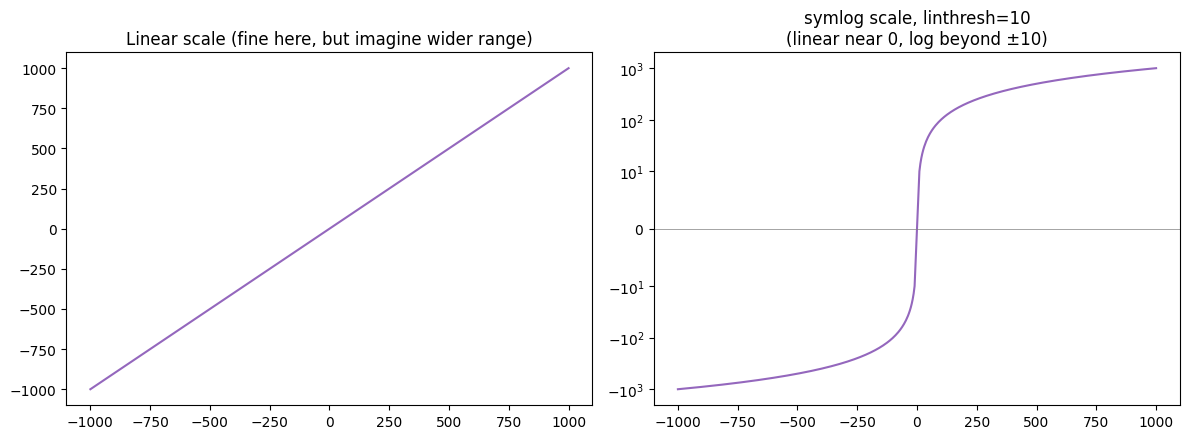

In [3]:
x_sym = np.linspace(-1000, 1000, 500)
y_sym = np.sign(x_sym) * (np.abs(x_sym)) ** 1.0   # spans -1000 to 1000, crossing zero

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(x_sym, y_sym, color="tab:purple")
axes[0].set_yscale("linear")
axes[0].set_title("Linear scale (fine here, but imagine wider range)")

axes[1].plot(x_sym, y_sym, color="tab:purple")
axes[1].set_yscale("symlog", linthresh=10)
axes[1].axhline(0, color="gray", linewidth=0.5)
axes[1].set_title("symlog scale, linthresh=10\n(linear near 0, log beyond ±10)")

plt.tight_layout()
plt.show()


### Parameter Explanation
- `linthresh` — the boundary (in data units, symmetric around zero) within which the scale stays **linear**; beyond `±linthresh`, it switches to logarithmic. Choosing this value is the main tuning decision — too small and you lose meaningful linear resolution near zero; too large and you lose the benefit of log compression for the extreme values.
- `linscale` — controls how much horizontal space the linear region near zero is given relative to each logarithmic decade (a secondary, rarely-needed tuning knob).

### Interpretation
Near zero, small residuals/values remain easy to distinguish (linear region); far from zero, large values are compressed logarithmically so they don't visually dominate the chart — giving you resolution at both scales simultaneously, something neither pure linear nor pure log can do for signed, wide-range data.

### Common Mistakes
- Reaching for `symlog` reflexively on any signed data, even when the range doesn't actually span multiple orders of magnitude — for modest ranges, it just adds unnecessary interpretive complexity versus a plain linear axis.
- Picking a `linthresh` far larger or smaller than the data's actual "interesting near-zero region," effectively collapsing back to either a fully linear or fully log-like appearance without the intended hybrid benefit.

### Best Practices
- Reserve `symlog` specifically for signed data spanning multiple orders of magnitude on both sides of zero (e.g., profit/loss across many business units of wildly different sizes).
- Choose `linthresh` based on the smallest magnitude of genuine analytical interest near zero — often the noise floor of your measurement.

### Interview Insight
**Q: You have model residuals ranging from -50,000 to +50,000, but most values cluster between -50 and +50 with a few huge outlier residuals. What scale would you use and why?**
A: `symlog` with `linthresh` set around the typical residual magnitude (e.g., `linthresh=50`) — this keeps the bulk of the residuals readable in the linear region near zero while still compressing the rare huge outliers logarithmically so they don't stretch the axis into uselessness for everything else.

### Mini Exercise
Re-plot the symlog example with `linthresh=100` instead of `10` and compare how much of the curve now falls in the linear (uncompressed) region versus the log-compressed region.

### Quiz (Chapter 37)
1. What problem does `symlog` solve that a pure `log` scale cannot?
2. What does `linthresh` control?
3. When should you avoid using `symlog` even on signed data?


---
# CHAPTER 38 — DATE/TIME VISUALIZATION

## 1. Concept
Matplotlib has dedicated support for datetime-typed x-axes: automatic "nice" date tick placement (`AutoDateLocator`) and formatting (`ConciseDateFormatter`/`DateFormatter`), so you don't have to manually compute tick positions for irregularly-spaced dates.

## 2. Why It Matters
Time series are ubiquitous in business and ML monitoring. Getting date axes wrong (illegible overlapping labels, wrong tick frequency, timezone bugs) is one of the most common "unprofessional-looking chart" causes in real reporting work.

## 3–4. NumPy / Pandas Connection
Pandas' `pd.date_range()` / `pd.to_datetime()` produce `Timestamp`-based indices/Series that Matplotlib understands natively — passing a `DatetimeIndex` directly to `ax.plot()` triggers Matplotlib's date-handling machinery automatically.


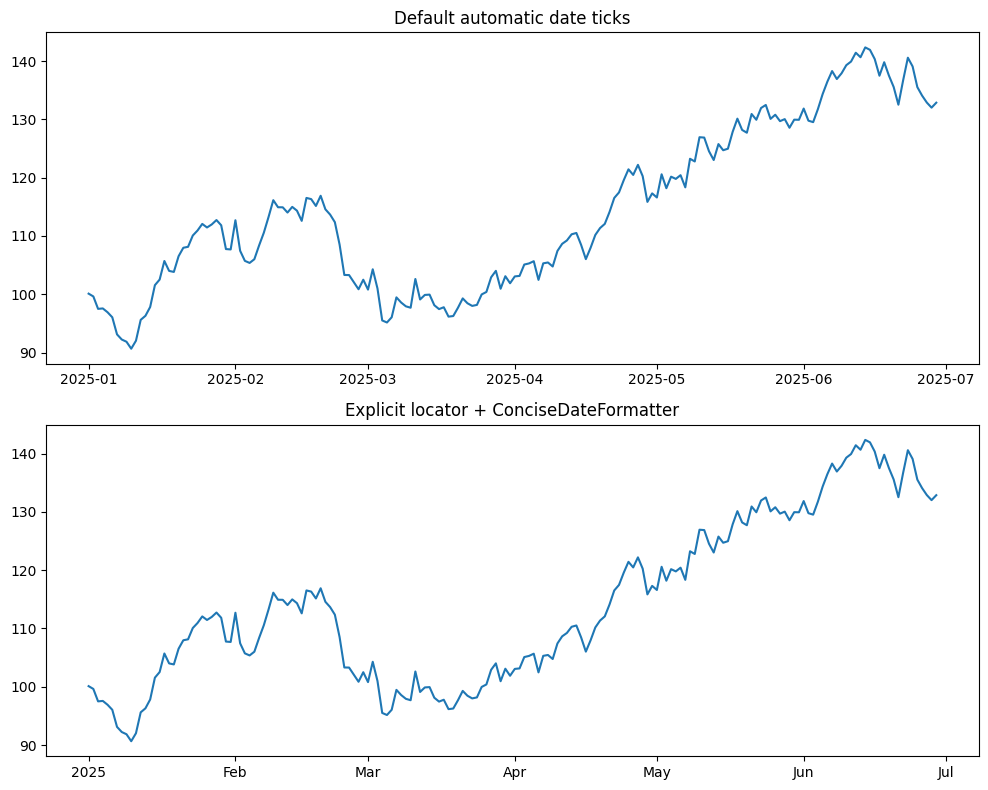

In [4]:
from matplotlib.dates import DateFormatter, AutoDateLocator, ConciseDateFormatter

dates = pd.date_range("2025-01-01", periods=180, freq="D")
np.random.seed(9)
metric = 100 + np.cumsum(np.random.normal(0.1, 2, size=180))
ts = pd.Series(metric, index=dates)

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Panel 1: default date handling (Matplotlib auto-detects the DatetimeIndex)
axes[0].plot(ts.index, ts.values, color="tab:blue")
axes[0].set_title("Default automatic date ticks")

# Panel 2: explicit, controlled formatting
axes[1].plot(ts.index, ts.values, color="tab:blue")
locator = AutoDateLocator()
formatter = ConciseDateFormatter(locator)   # compact, context-aware date labels
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(formatter)
axes[1].set_title("Explicit locator + ConciseDateFormatter")

plt.tight_layout()
plt.show()


### Parameter / API Explanation
- `AutoDateLocator()` — automatically chooses "nice" tick spacing (days/weeks/months/years) based on the plotted date range, similar in spirit to Matplotlib's default numeric tick locator but date-aware.
- `ConciseDateFormatter(locator)` — Matplotlib's modern recommended date formatter; it avoids redundant labels (e.g., only shows the year once when zoomed into a single year, instead of repeating it on every tick) — a significant readability upgrade over the older `DateFormatter`.
- `DateFormatter("%Y-%m-%d")` — for full manual control over the exact string format at every tick, when a specific format is required (e.g., a fixed report template).
- `ax.tick_params(axis="x", rotation=45)` — still commonly needed even with good locators, especially for dense date ranges.

### Internal Working
Internally, Matplotlib converts each date to a floating-point "days since an epoch" number (matching how `matplotlib.dates.date2num` works) before treating it exactly like any other numeric x-value for plotting purposes — the date-specific locator/formatter machinery only affects how **tick labels** are displayed, not how the underlying data is positioned.

### Common Mistakes
- Manually creating string tick labels for dates (`["Jan", "Feb", ...]`) instead of using the date-aware locators/formatters — breaks immediately if the date range or frequency changes, and doesn't handle irregular/missing dates gracefully.
- Not rotating tick labels on dense daily/weekly data — dates overlap and become illegible.
- Mixing timezone-aware and timezone-naive `Timestamp` objects in the same plot — can cause silent misalignment; keep timezone handling consistent throughout a project.

### Best Practices
- Prefer `ConciseDateFormatter` over manually specifying every tick's string format — it adapts intelligently to the zoom level and reduces redundant label text.
- Let Pandas' `DatetimeIndex` drive the x-axis directly rather than converting to strings first.

### Interview Insight
**Q: Why is `ConciseDateFormatter` generally preferred over manually formatting date tick strings?**
A: It automatically avoids redundant information across ticks (e.g., not repeating the year on every single monthly tick within one year) and adapts its format based on the actual zoom level/date range being displayed — producing consistently clean labels without hand-tuning the format string for every possible range a chart might be regenerated with.

### Mini Exercise
Zoom the date-axis example to just the first 14 days (`ax.set_xlim(dates[0], dates[13])`) and observe how `ConciseDateFormatter`'s tick labels automatically become more granular (showing day-level detail) compared to the full 180-day view.

### Quiz (Chapter 38)
1. What does Matplotlib actually store internally for a plotted date value?
2. Why is `ConciseDateFormatter` preferred over manual string ticks?
3. What Pandas object type, passed directly to `ax.plot()`, triggers Matplotlib's automatic date handling?


---
# CHAPTER 39 — MATPLOTLIB + PANDAS

## 1. Concept
Pandas ships a `.plot()` accessor on both `Series` and `DataFrame` objects — a thin convenience wrapper that calls Matplotlib internally with EDA-sensible defaults (auto-labeling from column names, auto-legends for multi-column DataFrames).

## 2. Why It Matters
`df.plot()` is genuinely faster for **quick, throwaway EDA** — one line instead of five. But it trades away fine-grained control, which is why production/report code still typically drops down to the explicit `fig, ax = plt.subplots()` + `ax.plot()` pattern.

## `df.plot()` vs Explicit Matplotlib — Side by Side


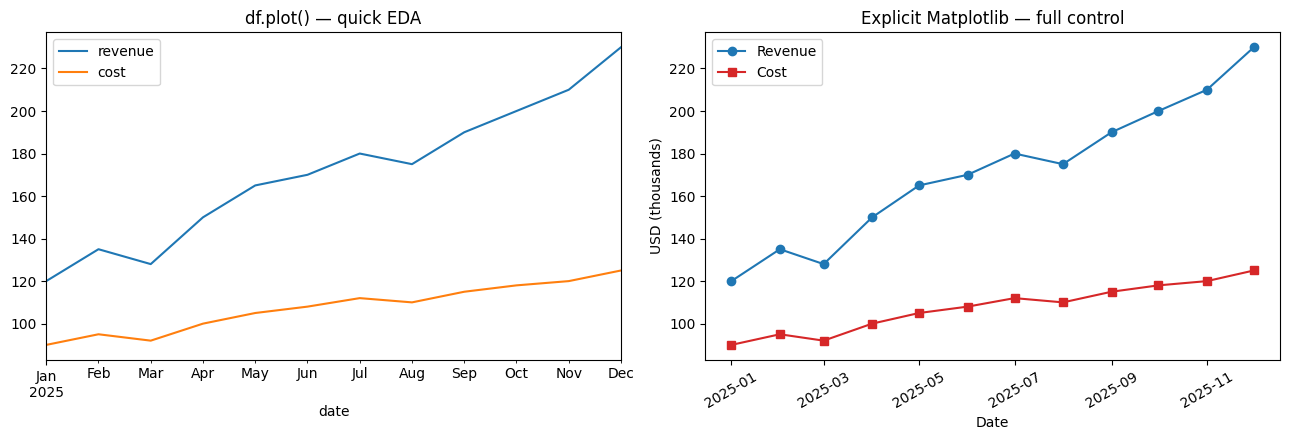

In [5]:
df_pd = pd.DataFrame({
    "date": pd.date_range("2025-01-01", periods=12, freq="MS"),
    "revenue": [120, 135, 128, 150, 165, 170, 180, 175, 190, 200, 210, 230],
    "cost": [90, 95, 92, 100, 105, 108, 112, 110, 115, 118, 120, 125],
}).set_index("date")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# --- Pandas convenience accessor: fast, auto-labeled, auto-legend ---
df_pd.plot(ax=axes[0])          # passing ax= keeps it inside OUR figure/subplot layout
axes[0].set_title("df.plot() — quick EDA")

# --- Explicit Matplotlib: full control ---
axes[1].plot(df_pd.index, df_pd["revenue"], color="tab:blue", marker="o", label="Revenue")
axes[1].plot(df_pd.index, df_pd["cost"], color="tab:red", marker="s", label="Cost")
axes[1].set_title("Explicit Matplotlib — full control")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("USD (thousands)")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- `df_pd.plot(ax=axes[0])` — the `ax=` argument is the critical piece that lets Pandas' convenience method participate in a larger, explicitly-managed Figure/subplot layout rather than always creating its own standalone figure. **Without `ax=`, `df.plot()` creates a brand-new Figure**, which is usually not what you want inside a multi-panel dashboard.
- Pandas' `.plot()` internally inspects the DataFrame's **columns** (using each column name as the auto-generated legend label) and its **index** (used as the x-axis, auto-detecting the `DatetimeIndex` for date formatting) — then issues the equivalent `ax.plot()` calls under the hood.

### What Pandas' `.plot()` Uses Internally
`df.plot()` is implemented via `pandas.plotting._matplotlib`, which — for a line plot — ultimately calls `ax.plot()` once per column, using the DataFrame's index as x and applying Matplotlib's default color cycle across columns, plus automatic legend/label generation from column names.

### `.plot(kind=...)` — Other Chart Types via the Same Accessor


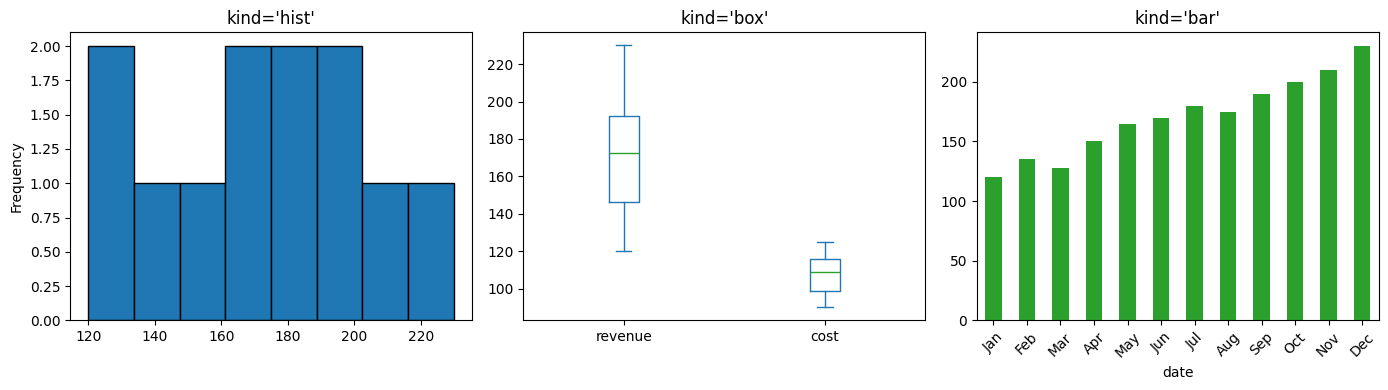

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

df_pd["revenue"].plot(kind="hist", bins=8, ax=axes[0], color="tab:blue", edgecolor="black")
axes[0].set_title("kind='hist'")

df_pd[["revenue", "cost"]].plot(kind="box", ax=axes[1])
axes[1].set_title("kind='box'")

# For kind='bar' with a DatetimeIndex, Pandas needs string labels rather than raw Timestamps
df_pd_str_idx = df_pd.copy()
df_pd_str_idx.index = df_pd_str_idx.index.strftime("%b")
df_pd_str_idx["revenue"].plot(kind="bar", ax=axes[2], color="tab:green")
axes[2].set_title("kind='bar'")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


### Parameter Explanation
| Parameter | Meaning |
|---|---|
| `kind` | Chart type: `'line'` (default), `'bar'`, `'barh'`, `'hist'`, `'box'`, `'scatter'`, `'area'`, `'pie'`, `'kde'` |
| `ax` | Pass an existing Matplotlib Axes to draw into (critical for multi-panel layouts) |
| `subplots` | If `True` on a multi-column DataFrame, draws one subplot per column automatically instead of overlaying them |
| `figsize`, `title`, `legend`, `grid` | Pass-through convenience shortcuts, equivalent to the Matplotlib calls you'd otherwise make manually |

### When to Use Which
| Situation | Use |
|---|---|
| Fast, throwaway EDA in a notebook | `df.plot()` |
| Need custom colors/styling/annotations | Explicit `fig, ax = plt.subplots()` |
| Building a reusable `visualization.py` function (Chapter 87) | Explicit Matplotlib (testable, composable) |
| Multi-panel dashboard combining Pandas convenience + custom panels | Both — `df.plot(ax=...)` inside a manually-built subplot grid, as shown above |

### Common Mistakes
- Calling `df.plot()` repeatedly inside a loop without `ax=` — creates a new, separate Figure on every call instead of reusing/updating one, silently generating far more figures than intended.
- Assuming `df.plot()` output is infinitely customizable — it returns a standard Matplotlib `Axes` object, so all the usual `ax.set_title()`/`ax.legend()` calls still work on it afterward, but some Pandas-specific auto-behaviors (like auto-legend placement) can be awkward to override cleanly compared to just building the chart in Matplotlib directly.

### Best Practices
- Use `df.plot()` freely during initial, single-person EDA exploration.
- Switch to explicit `fig, ax = plt.subplots()` + `ax.plot()` the moment a chart needs to be: shared/reused, precisely styled, part of a larger dashboard, or turned into a reusable function.

### Interview Insight
**Q: What does `df.plot()` actually call internally, and what critical argument should you pass when building a multi-panel figure?**
A: It's a thin wrapper that ultimately issues standard `ax.plot()` (or `ax.hist()`, `ax.bar()`, etc., depending on `kind`) calls using the DataFrame's columns and index for data/labels. The critical argument is `ax=` — passing an existing Axes object makes Pandas draw into that specific subplot rather than silently creating and returning a brand-new standalone Figure.

### Mini Exercise
Call `df_pd.plot(kind="scatter", x="cost", y="revenue")` and compare the one-liner's output to manually writing the equivalent `ax.scatter(df_pd["cost"], df_pd["revenue"])` call.

### Quiz (Chapter 39)
1. What critical parameter should you pass to `df.plot()` when it needs to participate in an existing multi-panel Figure?
2. What does Pandas' `.plot()` use as the default legend labels for a multi-column DataFrame?
3. When would you deliberately choose explicit Matplotlib over `df.plot()`?


---
# CHAPTER 40 — MATPLOTLIB + NUMPY

## 1. Concept
Beyond simply passing arrays as `x`/`y`, NumPy is Matplotlib's computational partner for anything requiring **numerical generation, transformation, or simulation** before visualization — sampling distributions, evaluating mathematical functions, building matrices for heatmaps, and vectorized array manipulation feeding directly into plotting calls.

## 2. Why It Matters
Nearly every non-trivial chart in this course has depended on NumPy to *produce* the data being visualized (`np.linspace`, `np.random.normal`, `np.cumsum`, `np.argsort`, `np.arange`) — this chapter consolidates that pattern explicitly as its own topic.


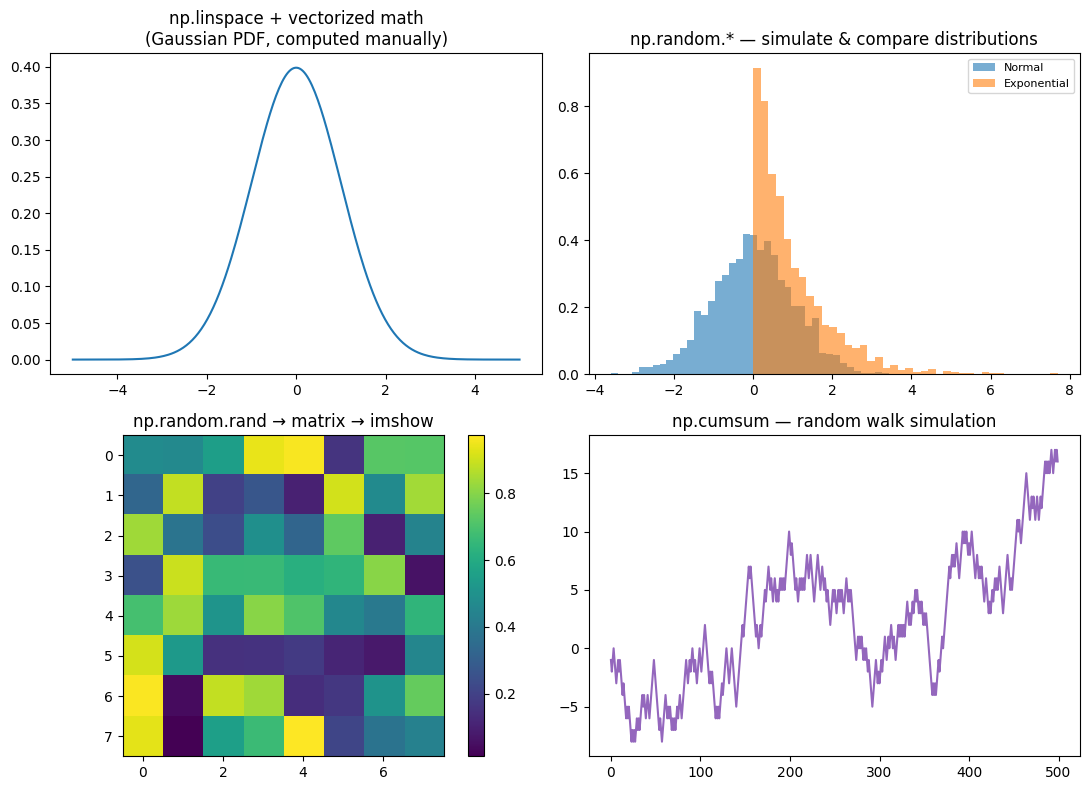

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

# 1) Mathematical function evaluation
x_np = np.linspace(-5, 5, 300)
axes[0, 0].plot(x_np, np.exp(-x_np**2 / 2) / np.sqrt(2 * np.pi), color="tab:blue")
axes[0, 0].set_title("np.linspace + vectorized math\n(Gaussian PDF, computed manually)")

# 2) Random sampling from multiple distributions
axes[0, 1].hist(np.random.normal(0, 1, 2000), bins=40, alpha=0.6, label="Normal", density=True)
axes[0, 1].hist(np.random.exponential(1, 2000), bins=40, alpha=0.6, label="Exponential", density=True)
axes[0, 1].set_title("np.random.* — simulate & compare distributions")
axes[0, 1].legend(fontsize=8)

# 3) Matrix visualization
matrix = np.random.rand(8, 8)
im = axes[1, 0].imshow(matrix, cmap="viridis")
axes[1, 0].set_title("np.random.rand → matrix → imshow")
fig.colorbar(im, ax=axes[1, 0])

# 4) Cumulative simulation (random walk)
steps = np.random.choice([-1, 1], size=500)
walk = np.cumsum(steps)
axes[1, 1].plot(walk, color="tab:purple")
axes[1, 1].set_title("np.cumsum — random walk simulation")

plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- **Panel 1**: `np.exp(-x_np**2 / 2) / np.sqrt(2 * np.pi)` computes the Gaussian probability density function directly via vectorized NumPy math (no library shortcut) — demonstrating that `ax.plot()` doesn't care whether `y` came from `np.sin()`, a hand-written formula, or a model's predictions; it's just an array.
- **Panel 2**: `np.random.normal()`/`np.random.exponential()` generate synthetic samples used to visually compare distribution shapes — a common technique for building intuition about a distribution family before applying it to real data, or for simulating expected behavior under a null hypothesis.
- **Panel 3**: `np.random.rand(8, 8)` produces an 8×8 array of values in `[0, 1)`, visualized directly as a heatmap via `ax.imshow()` (full heatmap treatment in Chapter 46) — matrices map onto images essentially for free.
- **Panel 4**: `np.cumsum(np.random.choice([-1, 1], size=500))` is the canonical NumPy one-liner for simulating a random walk — each step is ±1, and the cumulative sum traces the walk's position over time.

### Internal Working
None of this is Matplotlib-specific machinery — every panel demonstrates the same underlying contract: **Matplotlib's plotting functions are agnostic to how their input arrays were produced.** Whether an array comes from a closed-form NumPy computation, a random simulation, or (as in later ML chapters) a trained model's `.predict()` output, the plotting call itself (`ax.plot()`, `ax.hist()`, `ax.imshow()`) is identical.

### Common Mistakes
- Forgetting `np.random.seed()` when a simulation-based chart needs to be **reproducible** across re-runs (e.g., for a report that shouldn't change every time the notebook is re-executed) — always seed random generation used for illustrative/demo purposes.
- Using Python `for` loops to build arrays element-by-element before plotting, instead of vectorized NumPy operations — works but is slower and more verbose; the vectorized form (as used in every panel above) is both faster and the idiomatic professional style.

### Best Practices
- Treat "generate/transform with NumPy, then hand the resulting array to Matplotlib" as the standard mental pipeline for any chart that isn't directly sourced from a raw dataset.
- Seed random number generation for any figure meant to be reproducible or included in a report/portfolio.

### Interview Insight
**Q: Does Matplotlib care whether the `y` array passed to `ax.plot()` came from real data, a mathematical formula, or a random simulation?**
A: No — `ax.plot()` (and virtually every other Matplotlib plotting function) is agnostic to the *provenance* of its input arrays; it only cares about their shape and dtype. This is precisely why the same small set of Matplotlib calls serves EDA, mathematical visualization, simulation, and ML model diagnostics equally well — the visualization layer is fully decoupled from how the numbers were produced.

### Mini Exercise
Modify the random-walk panel to run and overlay 5 independent walks (5 separate `np.cumsum(np.random.choice(...))` calls) on the same Axes, to visually build intuition for how much individual random walks can diverge from each other.

### Quiz (Chapter 40)
1. Why doesn't Matplotlib care how an input array was generated?
2. What NumPy function is the standard one-liner for simulating a random walk?
3. Why should you `np.random.seed()` before generating data for an illustrative chart in a report?


---
# CHAPTER 41 — EDA WITH MATPLOTLIB (COMPLETE WORKFLOW)

## 1. Concept
A repeatable EDA visualization workflow, tying together everything from Notebooks 1–5:

```
Dataset → Shape/dtypes → Missing values → Numerical features → Categorical features
       → Distributions (univariate) → Relationships (bivariate/multivariate)
       → Outliers → Target analysis → Feature analysis → Insights
```

## 2. Why It Matters
Ad-hoc, unstructured EDA misses things — a repeatable checklist-driven workflow ensures every dataset gets the same baseline scrutiny before modeling begins, catching data-quality issues early (when they're cheap to fix) rather than after a model has already been trained on flawed data.

## Building a Realistic Dataset


In [8]:
np.random.seed(123)
n = 500
eda_df = pd.DataFrame({
    "customer_id": np.arange(1, n + 1),
    "age": np.random.normal(38, 12, n).clip(18, 80).round(0),
    "monthly_spend": np.random.exponential(150, n).round(2),
    "tenure_months": np.random.exponential(20, n).round(1),
    "region": np.random.choice(["North", "South", "East", "West"], n, p=[0.3, 0.25, 0.25, 0.2]),
    "plan_type": np.random.choice(["Basic", "Standard", "Premium"], n, p=[0.5, 0.35, 0.15]),
    "churned": np.random.choice([0, 1], n, p=[0.78, 0.22]),
})
# Inject some realistic missing values
missing_idx = np.random.choice(eda_df.index, size=25, replace=False)
eda_df.loc[missing_idx, "monthly_spend"] = np.nan

print("Shape:", eda_df.shape)
print()
print(eda_df.dtypes)


Shape: (500, 7)

customer_id        int64
age              float64
monthly_spend    float64
tenure_months    float64
region            object
plan_type         object
churned            int64
dtype: object


### Step 1 — Missing Values Visualization

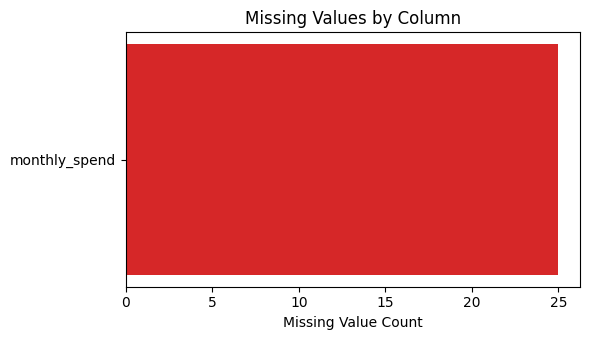

In [9]:
missing_counts = eda_df.isna().sum()
missing_counts = missing_counts[missing_counts > 0]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(missing_counts.index, missing_counts.values, color="tab:red")
ax.set_xlabel("Missing Value Count")
ax.set_title("Missing Values by Column")
plt.tight_layout()
plt.show()


### Step 2 — Numerical Feature Distributions (Univariate, Batch)

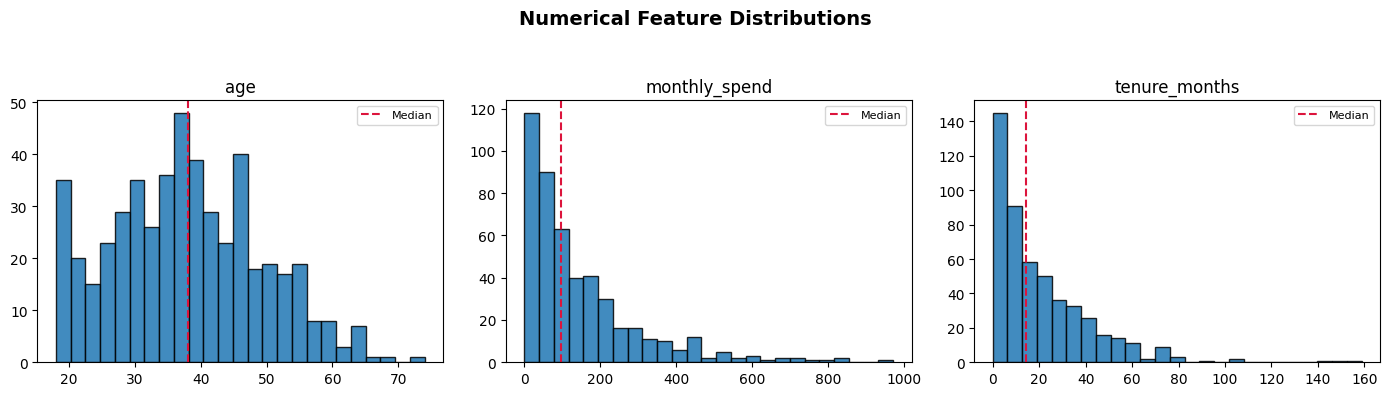

In [10]:
numerical_features = ["age", "monthly_spend", "tenure_months"]

fig, axes = plt.subplots(1, len(numerical_features), figsize=(14, 4))
for ax, col in zip(axes, numerical_features):
    ax.hist(eda_df[col].dropna(), bins=25, color="tab:blue", edgecolor="black", alpha=0.85)
    ax.set_title(col)
    ax.axvline(eda_df[col].median(), color="crimson", linestyle="--", linewidth=1.5, label="Median")
    ax.legend(fontsize=8)

fig.suptitle("Numerical Feature Distributions", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


### Step 3 — Categorical Feature Frequencies

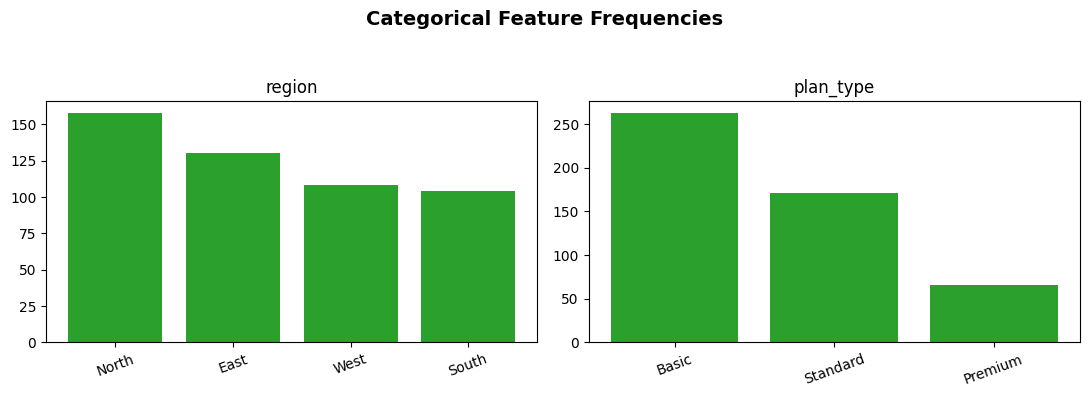

In [11]:
categorical_features = ["region", "plan_type"]

fig, axes = plt.subplots(1, len(categorical_features), figsize=(11, 4))
for ax, col in zip(axes, categorical_features):
    counts = eda_df[col].value_counts().sort_values(ascending=False)
    ax.bar(counts.index, counts.values, color="tab:green")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=20)

fig.suptitle("Categorical Feature Frequencies", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()


### Step 4 — Target Analysis (Class Balance)

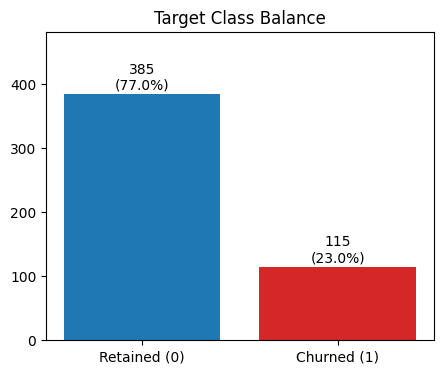

In [12]:
churn_counts = eda_df["churned"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["Retained (0)", "Churned (1)"], churn_counts.values, color=["tab:blue", "tab:red"])
for bar in bars:
    h = bar.get_height()
    pct = h / len(eda_df) * 100
    ax.annotate(f"{h}\n({pct:.1f}%)", xy=(bar.get_x() + bar.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=10)
ax.set_ylim(0, churn_counts.max() * 1.25)
ax.set_title("Target Class Balance")
plt.show()


### Interpretation of the Full Workflow
- **Missing values**: only `monthly_spend` has gaps (25 rows, ~5%) — small enough to consider imputation rather than dropping rows entirely, but worth confirming *why* those specific rows are missing (missing-completely-at-random vs. a systematic pattern — Chapter 69 covers this in depth).
- **Numerical distributions**: `monthly_spend` and `tenure_months` are right-skewed (exponential-like) — the median line sitting well left of any long tail is the quick visual tell; this skew is a signal that a log-transform might help certain downstream models, and that mean-based summaries would be misleading here.
- **Categorical frequencies**: `plan_type` is imbalanced toward "Basic" — worth keeping in mind for any model that treats plan type as a feature.
- **Target balance**: ~22% churn is a real but moderate class imbalance — not extreme, but enough that accuracy alone would be a misleading model metric (foreshadowing Chapter 51+'s classification visualization chapters, where precision/recall/PR-curves become essential specifically because of this kind of imbalance).

### Common Mistakes
- Skipping the missing-value check and only discovering `NaN`s during model training, as a cryptic error, rather than during EDA.
- Interpreting a skewed distribution's mean as "typical" — always cross-check the median (and the shape, visually) before trusting a single summary statistic (this is the Datasaurus Dozen lesson from Chapter 1, applied concretely).
- Not checking target class balance before choosing evaluation metrics.

### Best Practices
- Run this exact sequence (missing → univariate numerical → univariate categorical → target) as a repeatable **first four cells** of every new project notebook — consistency here catches issues early and cheaply.
- Batch-plot all numerical/categorical features via a `for` loop over subplots (as done above) rather than one-off individual cells per column — scales cleanly as the dataset grows.

### Interview Insight
**Q: Walk through your standard first-hour EDA visualization checklist on a brand-new dataset.**
A: Check shape/dtypes, visualize missing values per column, plot univariate distributions for every numerical feature (histograms, watching for skew/multi-modality), plot frequency bars for every categorical feature (watching for imbalance/rare categories), and — if there's a target column — check its class balance or distribution before anything else, since that shapes which evaluation metrics will even be meaningful later.

### Mini Exercise
Add a 4th numerical feature (e.g., `customer_id` shouldn't be treated as meaningful, but try adding a genuinely new simulated feature) to `numerical_features` and confirm the batch-plotting loop scales automatically with zero other code changes.

### Quiz (Chapter 41)
1. What's the standard order of a repeatable EDA visualization workflow?
2. Why does the median matter as much as (or more than) the mean for a skewed distribution?
3. Why does checking target class balance early affect which metrics you'll trust later?


---
# CHAPTER 42 — UNIVARIATE ANALYSIS

## 1. Concept
Univariate analysis examines **one variable at a time** — its central tendency, spread, shape, and outliers — using the single-variable chart types covered across Notebooks 1–3.

## Chart Selection for Univariate Analysis
| Variable type | Primary chart | Secondary/complementary chart |
|---|---|---|
| Numerical | Histogram | Box plot (for outliers/spread), KDE (for smooth shape) |
| Categorical | Bar chart (frequency count) | Horizontal bar if many/long-named categories |


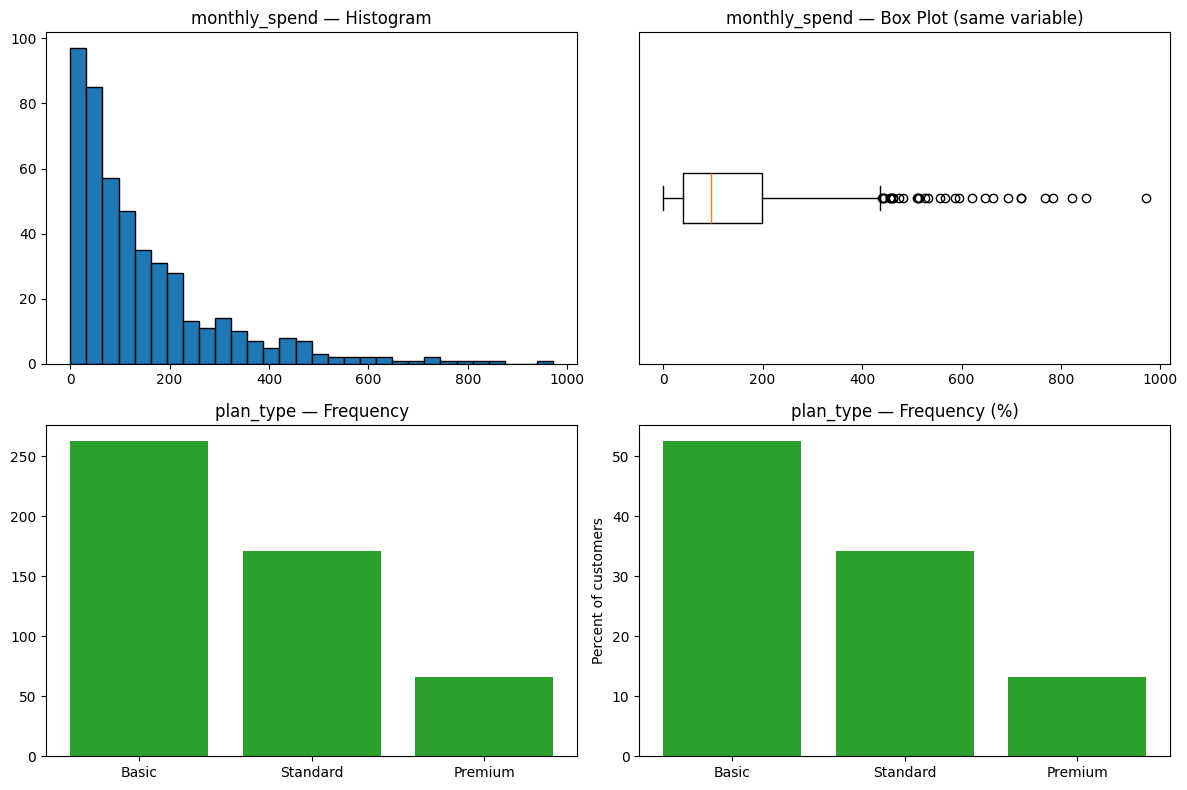

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Numerical: histogram + box plot combo for ONE variable — a very common professional pairing
axes[0, 0].hist(eda_df["monthly_spend"].dropna(), bins=30, color="tab:blue", edgecolor="black")
axes[0, 0].set_title("monthly_spend — Histogram")

axes[0, 1].boxplot(eda_df["monthly_spend"].dropna(), vert=False)
axes[0, 1].set_title("monthly_spend — Box Plot (same variable)")
axes[0, 1].set_yticks([])

# Categorical: frequency bar, sorted
plan_counts = eda_df["plan_type"].value_counts().sort_values(ascending=False)
axes[1, 0].bar(plan_counts.index, plan_counts.values, color="tab:green")
axes[1, 0].set_title("plan_type — Frequency")

# Categorical: same data as a proportion (often more interpretable)
axes[1, 1].bar(plan_counts.index, plan_counts.values / len(eda_df) * 100, color="tab:green")
axes[1, 1].set_ylabel("Percent of customers")
axes[1, 1].set_title("plan_type — Frequency (%)")

plt.tight_layout()
plt.show()


### Interpretation
Pairing a numerical variable's histogram (Panel 1) with its box plot (Panel 2, same variable) on the same row is a deliberately common professional habit: the histogram shows full distribution *shape* (here, clearly right-skewed with a long tail), while the box plot on the identical data explicitly flags the numeric outlier threshold and individual outlier points that are harder to eyeball precisely from bars alone. Neither chart alone tells the complete univariate story as efficiently as the pair does.

### Common Mistakes
- Only ever looking at ONE chart type per variable — e.g., only a box plot (missing multi-modality, since a box plot's 5-number summary can't reveal it — recall Chapter 22) or only a histogram (missing a precise outlier count/threshold, which a box plot states explicitly).
- Reporting raw counts for categorical frequencies when the audience needs proportions (%) to compare against a benchmark, or vice versa — check which framing the analytical question actually calls for.

### Best Practices
- For any numerical variable central to the analysis, generate **both** a histogram and a box plot as a matched pair — the combined view is more diagnostic than either alone.
- Sort categorical frequency bars by count, always, unless there's a specific non-frequency-based natural order (e.g., a Likert scale) that matters more for the audience.

### Interview Insight
**Q: For a single important numerical variable, why might you generate both a histogram and a box plot rather than just one?**
A: They surface complementary information: the histogram reveals the full shape (skew, multi-modality) that a box plot's 5-number summary cannot show, while the box plot explicitly and precisely flags the exact outlier threshold and individual outlier points that are hard to judge by eye from histogram bars alone. Together they give a more complete univariate picture than either alone.

### Mini Exercise
Generate the histogram + box plot pair for `age` and `tenure_months` as well, and note (in a markdown cell) which of the three numerical variables shows the most pronounced skew.

### Quiz (Chapter 42)
1. What two chart types are commonly paired for a single important numerical variable, and why?
2. When would you report categorical frequencies as percentages rather than raw counts?
3. What univariate structure can a box plot miss that a histogram reveals?


---
# CHAPTER 43 — BIVARIATE ANALYSIS

## 1. Concept
Bivariate analysis examines the **relationship between exactly two variables**. The correct chart depends entirely on the combination of variable types involved.

## Chart Selection for Bivariate Analysis
| Combination | Chart |
|---|---|
| Numerical vs Numerical | Scatter plot |
| Numerical vs Categorical | Grouped box plot / violin plot (one box per category) |
| Categorical vs Categorical | Grouped or stacked bar chart of cross-tabulated counts |


/tmp/ipykernel_766/2058236915.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(groups, labels=["Basic", "Standard", "Premium"])


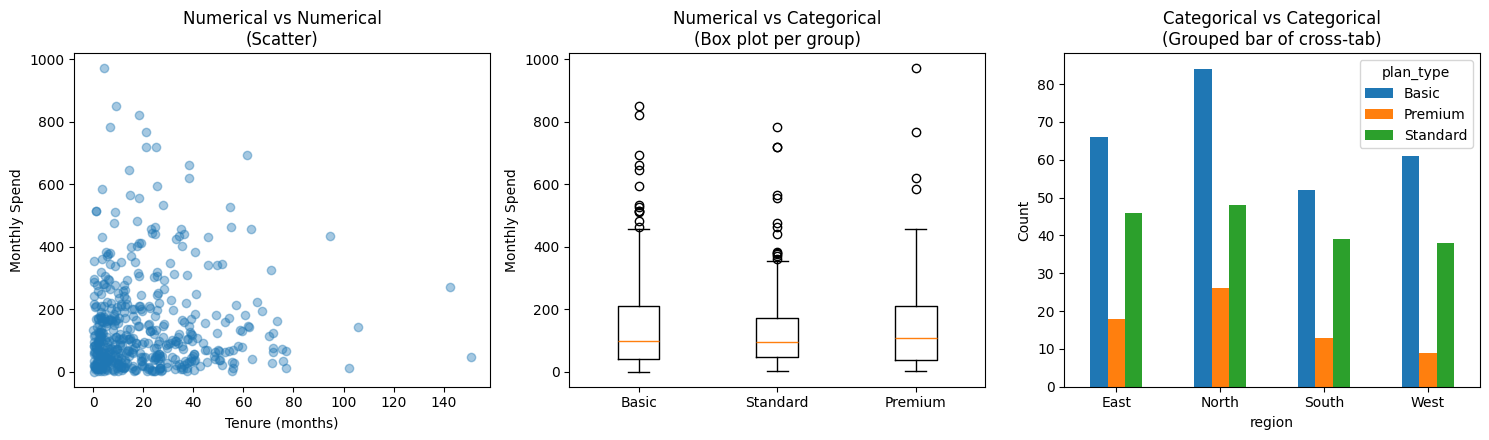

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Numerical vs Numerical
axes[0].scatter(eda_df["tenure_months"], eda_df["monthly_spend"], alpha=0.4, color="tab:blue")
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Monthly Spend")
axes[0].set_title("Numerical vs Numerical\n(Scatter)")

# Numerical vs Categorical
groups = [eda_df.loc[eda_df["plan_type"] == p, "monthly_spend"].dropna() for p in ["Basic", "Standard", "Premium"]]
axes[1].boxplot(groups, labels=["Basic", "Standard", "Premium"])
axes[1].set_ylabel("Monthly Spend")
axes[1].set_title("Numerical vs Categorical\n(Box plot per group)")

# Categorical vs Categorical
crosstab = pd.crosstab(eda_df["region"], eda_df["plan_type"])
crosstab.plot(kind="bar", ax=axes[2])
axes[2].set_title("Categorical vs Categorical\n(Grouped bar of cross-tab)")
axes[2].set_ylabel("Count")
axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


### Line-by-Line Explanation
- **Panel 1**: A direct scatter — no aggregation, every individual customer plotted, correct for two numerical variables.
- **Panel 2**: `[eda_df.loc[eda_df["plan_type"] == p, "monthly_spend"] for p in [...]]` builds the required **list of arrays** (recall Chapter 22's requirement) — one array of spend values per plan-type category — feeding directly into `ax.boxplot()` for a clean numerical-vs-categorical comparison.
- **Panel 3**: `pd.crosstab(region, plan_type)` produces a 2D count table (rows = region, columns = plan_type); calling `.plot(kind="bar")` directly on that crosstab DataFrame (Chapter 39's `df.plot()` pattern) auto-generates a grouped bar chart — one bar cluster per region, one bar per plan type within each cluster — with zero manual offset math needed (Pandas handles the Chapter 17 offset logic internally for you here).

### Interpretation
- Panel 1: little to no visible linear relationship between tenure and spend in this synthetic data — a flat, uncorrelated cloud.
- Panel 2: Premium customers show visibly higher median monthly spend than Basic — an expected, sanity-confirming pattern (Premium should cost more) that validates the data's basic internal consistency.
- Panel 3: reveals whether certain regions skew toward certain plan types — e.g., if one region's customers disproportionately choose "Basic," that's an actionable regional-marketing insight invisible from either variable's univariate view alone.

### Common Mistakes
- Using a scatter plot for a numerical-vs-categorical pair by numerically encoding the category (e.g., Basic=0, Standard=1, Premium=2) — the resulting scatter implies a false ordinal/numeric relationship between categories that likely doesn't exist; use grouped box/violin plots instead.
- Building a crosstab bar chart without first checking `pd.crosstab(..., normalize='index')` when relative composition (not raw counts) is the actual question — raw counts can be dominated by whichever category simply has more total customers.

### Best Practices
- Always identify both variables' types *before* picking a bivariate chart — the decision is fully determined by that combination, not by aesthetic preference.
- For categorical-vs-categorical, consider both the raw-count crosstab bar chart and a normalized (percentage) version, since they answer subtly different questions ("how many" vs. "what share").

### Interview Insight
**Q: You want to compare monthly spend across three subscription plan tiers. Why is a scatter plot (with plan tier numerically encoded 0/1/2) the wrong choice?**
A: Numerically encoding an unordered (or even ordinal-but-non-uniform) category and scattering against it implies false structure — evenly-spaced numeric positions and a continuous x-axis that doesn't actually exist for the categories, and a viewer might misread apparent "trends" along that axis as meaningful. A grouped box or violin plot (one distribution per category, positioned at genuinely discrete, unordered slots) is the correct encoding for numerical-vs-categorical comparison.

### Mini Exercise
Recreate Panel 3 using `pd.crosstab(eda_df["region"], eda_df["plan_type"], normalize="index")` (row-normalized to proportions) and compare what insight changes versus the raw-count version.

### Quiz (Chapter 43)
1. What determines the correct bivariate chart choice — the specific column names, or the pair of variable types involved?
2. Why is scattering against a numerically-encoded category usually wrong?
3. What single Pandas function produces the count table needed for a categorical-vs-categorical bar chart?


---
# CHAPTER 44 — MULTIVARIATE VISUALIZATION

## 1. Concept
Multivariate analysis visualizes **3 or more variables at once**, by combining multiple visual encoding channels (position, color, size, subplot) on top of each other — everything from Chapters 13–14 (scatter + color/size) and Chapter 28 (subplots) converges here.

## 2. Why It Matters
Real analytical questions are rarely truly two-dimensional — "does spend relate to tenure, and does that relationship differ by plan type, and does churn interact with both?" is a genuinely multivariate question requiring a genuinely multivariate visualization strategy.

## Encoding Channels Available (in rough order of how precisely humans read them)
1. **Position** (x, y) — most precise
2. **Length/size**
3. **Color/hue** (best for a small number of categories)
4. **Shape/marker**
5. **Small multiples** (separate subplots — effectively adds an unlimited number of "categories" as separate panels, at the cost of direct overlay comparison)


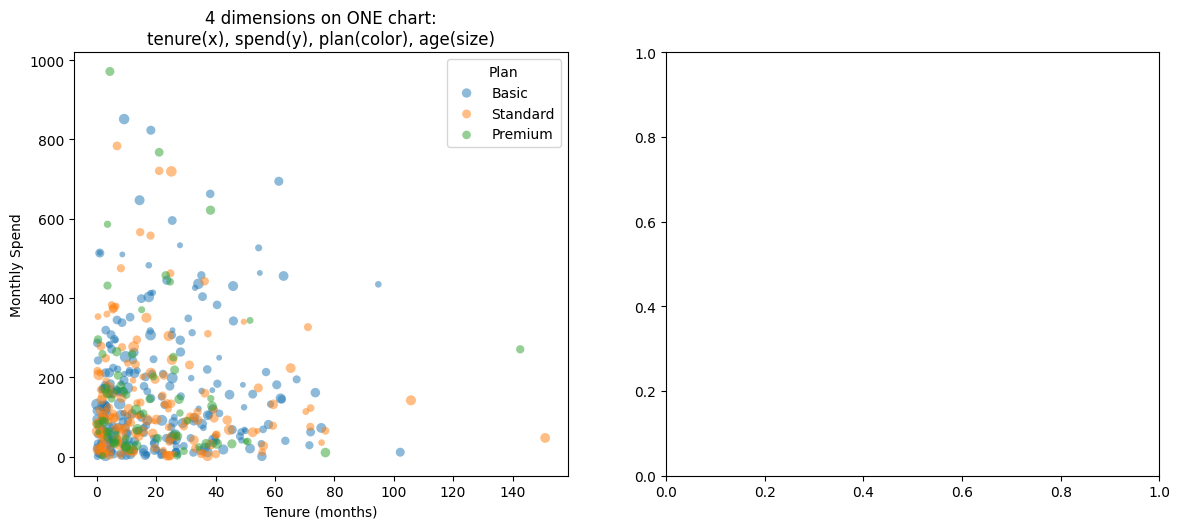

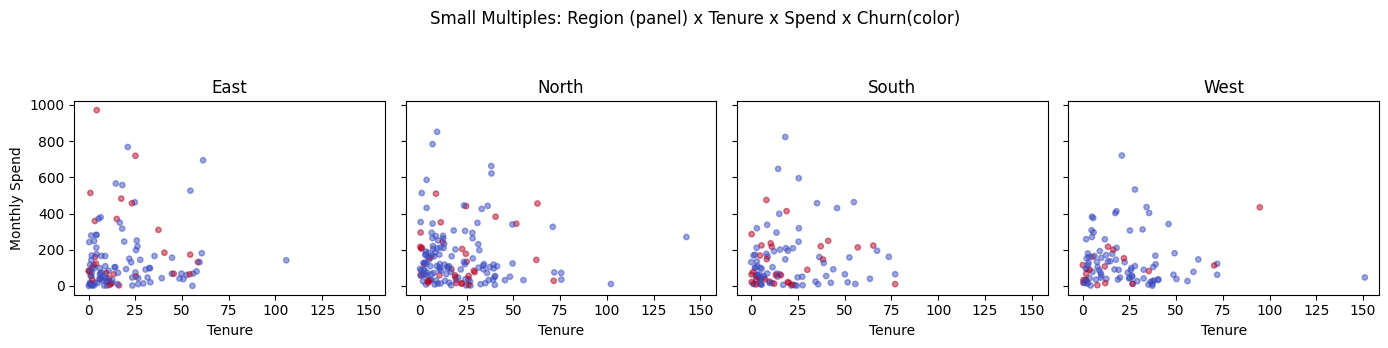

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Approach 1: color + size encode two additional variables on ONE scatter (4 total dimensions)
colors_map = {"Basic": "tab:blue", "Standard": "tab:orange", "Premium": "tab:green"}
for plan, color in colors_map.items():
    subset = eda_df[eda_df["plan_type"] == plan]
    axes[0].scatter(
        subset["tenure_months"], subset["monthly_spend"],
        s=subset["age"],                 # size encodes age (4th dimension)
        c=color, alpha=0.5, label=plan, edgecolors="none",
    )
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Monthly Spend")
axes[0].set_title("4 dimensions on ONE chart:\ntenure(x), spend(y), plan(color), age(size)")
axes[0].legend(title="Plan")

# Approach 2: small multiples — one subplot PER region, same x/y/color scheme repeated
regions_list = sorted(eda_df["region"].unique())
fig2, axes2 = plt.subplots(1, len(regions_list), figsize=(14, 3.5), sharey=True, sharex=True)
for ax_r, region in zip(axes2, regions_list):
    subset = eda_df[eda_df["region"] == region]
    ax_r.scatter(subset["tenure_months"], subset["monthly_spend"],
                 c=subset["churned"], cmap="coolwarm", alpha=0.5, s=15)
    ax_r.set_title(region)
    ax_r.set_xlabel("Tenure")
axes2[0].set_ylabel("Monthly Spend")
fig2.suptitle("Small Multiples: Region (panel) x Tenure x Spend x Churn(color)", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()


### Line-by-Line Explanation
- **Approach 1**: a single scatter Axes encoding **4 variables at once** — x=tenure, y=spend, color=plan (looped per-category for a clean legend, per Chapter 13's best practice), size=age. This is close to the practical ceiling for a single-panel multivariate chart before it becomes genuinely hard to read.
- **Approach 2**: `plt.subplots(1, len(regions_list), sharey=True, sharex=True)` — one subplot **per region**, effectively adding region as a 5th "dimension" via **small multiples** rather than cramming it into color/shape/size on top of the other four. `sharey=True`/`sharex=True` is essential here — it keeps all panels on identical scales, making cross-panel comparison valid (without it, each panel would auto-scale independently, making visual comparison misleading).

### Interpretation
Approach 1 lets you see, in one glance, whether Premium customers (green) tend to be both older (bigger markers) and higher-spending — a genuinely 4D pattern-spotting task. Approach 2 instead lets you compare whether the tenure-vs-spend relationship, and its churn coloring, looks structurally *different* across regions — a question that color/size alone couldn't answer as cleanly, because "does the whole relationship shift" is easier to see side-by-side than overlaid.

### Common Mistakes
- Cramming 5+ variables onto ONE overlaid chart (position × color × size × shape × line style simultaneously) — well past the point where a reader can reliably decode more than 2–3 of the encodings at once; this is "chart junk" territory (Chapter 78).
- Using small multiples **without** `sharex`/`sharey` — makes visual cross-panel comparison actively misleading, since each panel's axis range would differ based on its own subset's min/max.
- Choosing color to encode a **continuous** variable across many small multiples redundantly, when the same continuous variable might be better shown as one of the subplot's own axes instead.

### Best Practices
- Cap single-chart overlaid encodings at 3–4 variables (x, y, one categorical color, optionally one size/continuous dimension).
- Reach for small multiples the moment you need to add a *5th* practically-relevant grouping dimension — it scales far more gracefully than continuing to stack encoding channels on one panel.
- Always share axes (`sharex`/`sharey`) across small multiples meant for direct comparison.

### Interview Insight
**Q: You need to visualize how a two-variable relationship changes across 4 different customer segments. Would you use color to encode the segment, or small multiples (subplots)?**
A: It depends on how many *other* encoding channels are already in use. If color is still free (not already encoding something else) and there are only ~4 segments, an overlaid scatter with color-coded segments works and allows direct overlap comparison. But if color (or size) is already used for another variable, or if the *shape* of the whole relationship (not just point color) plausibly differs meaningfully by segment, small multiples with shared axes communicate that more reliably, since it's easier to compare 4 separate, axis-aligned panels than to disentangle 4 overlapping colored point clouds.

### Mini Exercise
Rebuild Approach 1 but add `marker` as a 5th encoding channel (different marker shape per some new binary split, e.g., churned vs not) and assess, in a markdown cell, whether the chart is still genuinely readable at 5 encoded dimensions.

### Quiz (Chapter 44)
1. List the encoding channels available for multivariate visualization, roughly ordered by how precisely humans read them.
2. Why is `sharex`/`sharey` essential for small multiples meant for direct comparison?
3. At roughly how many simultaneously-overlaid encoded variables does a single chart typically become unreadable?


---
# CHAPTER 45 — CORRELATION VISUALIZATION

## 1. Concept
`df.corr(numeric_only=True)` computes the pairwise Pearson correlation matrix across all numerical columns; visualizing that matrix (fully as a heatmap in Chapter 46) reveals which feature pairs move together, which is directly useful for feature selection and multicollinearity checks before modeling.

## 2. Why It Matters
Scanning a raw numerical correlation table (especially with 10+ features → 100+ cells) is slow and error-prone; a color-coded visual scan is dramatically faster at spotting the handful of strongly-correlated pairs that actually matter.

## 3–4. NumPy / Pandas Connection
`df.corr()` returns a square Pandas DataFrame; passed to `ax.imshow()`, its underlying NumPy array (`.values` / `.to_numpy()`) is what actually gets rendered as color.

## Critical Caveat: Correlation ≠ Causation
A strong correlation visualization is a hypothesis-generation tool, not a causal claim — this course will not turn into a statistics course, but this single caveat is essential every time a correlation chart is presented to a non-technical audience, who may otherwise over-interpret it.


In [16]:
np.random.seed(15)
corr_df = pd.DataFrame({
    "age": eda_df["age"],
    "monthly_spend": eda_df["monthly_spend"],
    "tenure_months": eda_df["tenure_months"],
    "churned": eda_df["churned"],
})
corr_matrix = corr_df.corr(numeric_only=True)
print(corr_matrix.round(2))


                age  monthly_spend  tenure_months  churned
age            1.00          -0.01          -0.04    -0.03
monthly_spend -0.01           1.00           0.03     0.03
tenure_months -0.04           0.03           1.00    -0.04
churned       -0.03           0.03          -0.04     1.00


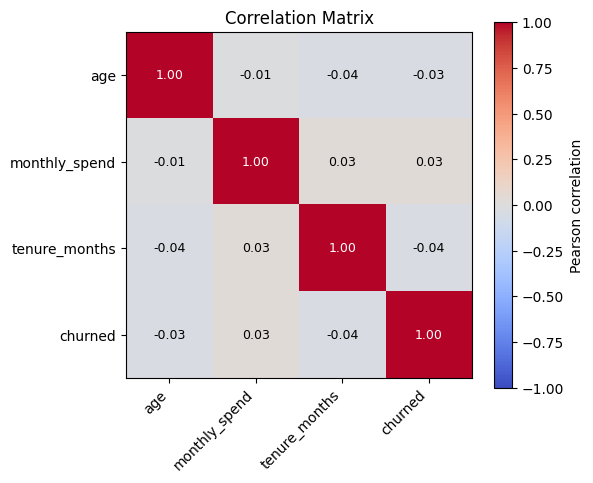

In [17]:
fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)   # diverging cmap, fixed range for correlation's [-1, 1] scale

ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_yticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=45, ha="right")
ax.set_yticklabels(corr_matrix.columns)

# Annotate each cell with its numeric value
for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr_matrix.iloc[i, j]) > 0.5 else "black", fontsize=9)

fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation Matrix")
plt.tight_layout()
plt.show()


### Line-by-Line / Parameter Explanation
- `cmap="coolwarm"` — a **diverging** colormap (Chapter 7) is the correct choice here specifically because correlation has a meaningful, symmetric midpoint (zero = no correlation), with two meaningfully-opposite directions (positive vs negative) — exactly the scenario diverging colormaps are designed for.
- `vmin=-1, vmax=1` — explicitly fixes the color scale to correlation's known theoretical range, rather than letting `imshow` auto-scale to just the min/max values actually present in this specific matrix. This is essential: without it, a matrix where the strongest correlation happens to be only 0.4 would have that 0.4 rendered as the most intense color, visually overstating a moderate relationship as if it were as strong as a perfect one.
- The nested `for i / for j` loop with `ax.text(j, i, ...)` — manually annotates every cell with its exact numeric value; note the color logic (`"white" if abs(value) > 0.5 else "black"`) which keeps text legible against both dark and light cells of the diverging colormap — a small but important readability detail.

### Internal Working
`ax.imshow(corr_matrix)` treats the 2D array exactly like a grayscale/color image, mapping each `(row, col)` value through the `Normalize` + colormap pipeline described in Chapter 7 — this is the same underlying mechanism as any other `imshow` heatmap (formalized fully in Chapter 46).

### Interpretation
`monthly_spend` and `tenure_months` show a specific correlation value directly readable off the diagonal-adjacent cell — check whether it's strongly positive, weakly positive, or near zero, and note that the diagonal is always exactly `1.00` (every variable perfectly correlates with itself) — a useful sanity check that the matrix was computed correctly. Any correlation near `±1` off the diagonal would be a **multicollinearity** warning sign worth investigating before feeding both features into certain model types (e.g., linear regression) unchanged.

### Common Mistakes
- Using a **sequential** colormap (e.g., `viridis`) instead of a diverging one for a correlation matrix — obscures the important distinction between positive and negative correlation, since a sequential map has no natural "zero" midpoint to visually anchor against.
- Omitting `vmin=-1, vmax=1` — lets weak correlations appear visually as strong as perfect ones, purely due to auto-scaling against whatever values happen to be present.
- Treating a strong correlation as proof of a causal relationship, or presenting it to stakeholders without that caveat — one of the most common analytical overreach mistakes in business reporting.
- Including a clearly non-meaningful numeric column (like a raw ID) in the correlation matrix by accident — `numeric_only=True` still includes any accidentally-numeric ID column, which typically has no real correlation with anything and just adds visual noise; explicitly drop such columns first.

### Best Practices
- Always use a diverging colormap with `vmin=-1, vmax=1` fixed explicitly for correlation matrices.
- Annotate cells with numeric values whenever the matrix is small enough (roughly ≤ 15×15) to remain legible with text overlaid.
- Always caveat correlation visualizations with "correlation is not causation" when presenting to a non-technical audience, and actively exclude non-meaningful numeric columns (IDs, etc.) before computing.

### Interview Insight
**Q: Why must a correlation heatmap's colormap be explicitly fixed to `vmin=-1, vmax=1` rather than left to auto-scale?**
A: Without fixing the range, `imshow`'s default `Normalize` behavior scales color intensity relative only to the min/max values actually present in that specific matrix — so if the strongest correlation present happens to be a moderate 0.4, it would be rendered with the same visual intensity as a perfect 1.0 correlation would be on a properly-scaled chart, misleadingly suggesting a much stronger relationship than actually exists. Fixing `vmin`/`vmax` to correlation's true theoretical range keeps color intensity comparable and honest across any dataset.

### Mini Exercise
Add `eda_df["customer_id"]` into `corr_df` before recomputing the correlation matrix, and observe (and explain, in a markdown cell) why its correlations with every other column are near zero and analytically meaningless.

### Quiz (Chapter 45)
1. Why is a diverging colormap the correct choice for a correlation matrix specifically?
2. Why must `vmin`/`vmax` be fixed explicitly rather than auto-scaled for this chart type?
3. What caveat must always accompany a correlation visualization shown to a non-technical audience?
4. What does the diagonal of any correlation matrix always equal, and why?

### Chapter 45 Summary
- Correlation matrices are the standard first check for feature relationships and multicollinearity before modeling.
- Diverging colormap + fixed `[-1, 1]` range + numeric annotation is the professional standard presentation.
- Full heatmap mechanics (colorbars, `imshow` parameters like `interpolation`/`aspect`/`origin`) get their own dedicated treatment in Chapter 46.

---

## END OF NOTEBOOK 5 — What You Should Now Be Able To Do
- Choose log vs symlog scales correctly, and read a log-scaled straight line as the signature of exponential growth.
- Build clean, correctly-formatted date-axis time series using Pandas `DatetimeIndex` + `ConciseDateFormatter`.
- Move fluidly between `df.plot()` (fast EDA) and explicit Matplotlib (full control, reusable functions), knowing when each is appropriate.
- Recognize that every chart in this course is downstream of a NumPy array, regardless of how that array was produced.
- Run a complete, repeatable EDA visualization workflow: missing values → univariate → bivariate → multivariate → correlation.
- Select the correct bivariate chart type from the variable-type combination alone.
- Build multivariate visualizations using layered encodings (color/size) and small multiples, while knowing the practical readability limits of each.
- Build a correctly-scaled, diverging, annotated correlation heatmap and interpret it responsibly (correlation ≠ causation).

## Before Moving to Notebook 6 (Chapters 46–55: Heatmaps with Matplotlib, Images/Matrices, Colorbars, Contour Plots, 3D Visualization, ML Visualization intro, Classification Model Visualization, Confusion Matrix, ROC Curve, Precision-Recall Curve) 